In [1]:
!pip install -q unsloth

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [4]:

import os
import glob
import random
import numpy as np
import pandas as pd
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# First try the expected filename in MyDrive.
filename = "/content/drive/MyDrive/Autoimmune_Dataset_Junior_Balanced_clean.csv"


candidates = glob.glob(
    f"/content/drive/MyDrive/**/{filename}",
    recursive=True
)

if not candidates:
    # Also find copies with suffixes such as (1).
    candidates = glob.glob(
        "/content/drive/MyDrive/Autoimmune_Dataset_Junior_Balanced_clean.csv",
        recursive=True
    )

if not candidates:
    raise FileNotFoundError(
        "Dataset CSV not found in Google Drive. "
        "Check that it is uploaded to MyDrive."
    )

# Use the exact filename when available.
exact = [p for p in candidates if os.path.basename(p) == filename]
dataset_path = exact[0] if exact else candidates[0]

print("Dataset:", dataset_path)

df = pd.read_csv(dataset_path)

print("Dataset shape:", df.shape)
print("\nDisease distribution:")
print(df["Disease"].value_counts(dropna=False))
print("\nNumber of classes:", df["Disease"].nunique())

Dataset: /content/drive/MyDrive/Autoimmune_Dataset_Junior_Balanced_clean.csv
Dataset shape: (4250, 25)

Disease distribution:
Disease
Normal                          2000
Rheumatoid Arthritis             250
Psoriatic Arthritis              250
Systemic Lupus Erythematosus     250
Multiple sclerosis               250
Ankylosing Spondylitis           250
Celiac disease                   250
Reactive Arthritis               250
Crohn's disease                  250
Sjögren's Syndrome               250
Name: count, dtype: int64

Number of classes: 10


In [5]:
if not torch.cuda.is_available():
    raise RuntimeError(
        "No NVIDIA GPU detected. Select a GPU runtime in Colab. "
        "This notebook is for Unsloth on GPU, not TPU."
    )

print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory:",
    round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3,
        2
    ),
    "GB"
)

expected_features = [
    "Age", "Gender", "ESR", "CRP", "RF", "Anti_CCP",
    "HLA_B27", "ANA", "Anti_Ro", "Anti_La",
    "Anti_dsDNA", "Anti_Sm", "C3", "C4", "ASCA",
    "Anti_CBir1", "Anti_OmpC", "pANCA", "EMA", "DGP",
    "Anti_tTG", "Anti_TPO", "Anti_SMA"
]

required_columns = expected_features + ["Disease"]

missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {sorted(missing_columns)}"
    )

if df[required_columns].isnull().any().any():
    raise ValueError(
        "Missing values detected in the clinical features or Disease. "
        "Inspect the dataset before training."
    )

classes = sorted(df["Disease"].astype(str).unique())

if len(classes) != 10:
    raise ValueError(
        f"Expected 10 classes (9 diseases + Normal), "
        f"but found {len(classes)}: {classes}"
    )

if not any(label.strip().casefold() == "normal" for label in classes):
    raise ValueError("Normal class is missing from the dataset.")

df["Disease"] = df["Disease"].astype(str)

print("Verified 23 input features.")
print("Verified 10 classes:")
for label in classes:
    print("-", label)

GPU: Tesla T4
GPU memory: 14.56 GB
Verified 23 input features.
Verified 10 classes:
- Ankylosing Spondylitis
- Celiac disease
- Crohn's disease
- Multiple sclerosis
- Normal
- Psoriatic Arthritis
- Reactive Arthritis
- Rheumatoid Arthritis
- Sjögren's Syndrome
- Systemic Lupus Erythematosus


In [7]:
from sklearn.model_selection import train_test_split

# Keep original row IDs so we can verify no overlap.
df = df.copy()
df["_source_row_id"] = np.arange(len(df))

train_full, test_full = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["Disease"]
)

train_full = train_full.copy()
test_full = test_full.copy()

# Verify the original partitions do not overlap.
assert set(train_full["_source_row_id"]).isdisjoint(
    set(test_full["_source_row_id"])
)

# Take 100 training examples from each of the 10 classes.
train_parts = []

for label in classes:
    group = train_full[train_full["Disease"] == label]

    if len(group) < 100:
        raise ValueError(
            f"Insufficient training rows for {label}: {len(group)}"
        )

    train_parts.append(
        group.sample(n=1e0, random_state=SEED)
    )

train_1500 = (
    pd.concat(train_parts)
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)

# Take 30 test examples from each class.
test_parts = []

for label in classes:
    group = test_full[test_full["Disease"] == label]

    if len(group) < 30:
        raise ValueError(
            f"Insufficient test rows for {label}: {len(group)}"
        )

    test_parts.append(
        group.sample(n=30, random_state=SEED)
    )

test_300 = (
    pd.concat(test_parts)
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)

# Critical: verify overlap using original source IDs.
train_ids = set(train_1500["_source_row_id"])
test_ids = set(test_300["_source_row_id"])

assert len(train_1500) == 1500
assert len(test_300) == 300
assert train_ids.isdisjoint(test_ids)

print("Fine-tuning samples:", len(train_1500))
print("Testing samples:", len(test_300))
print("Overlapping source rows:", len(train_ids & test_ids))

print("\nFine-tuning distribution:")
print(train_1500["Disease"].value_counts().sort_index())

print("\nTesting distribution:")
print(test_300["Disease"].value_counts().sort_index())

Fine-tuning samples: 1500
Testing samples: 300
Overlapping source rows: 0

Fine-tuning distribution:
Disease
Ankylosing Spondylitis          150
Celiac disease                  150
Crohn's disease                 150
Multiple sclerosis              150
Normal                          150
Psoriatic Arthritis             150
Reactive Arthritis              150
Rheumatoid Arthritis            150
Sjögren's Syndrome              150
Systemic Lupus Erythematosus    150
Name: count, dtype: int64

Testing distribution:
Disease
Ankylosing Spondylitis          30
Celiac disease                  30
Crohn's disease                 30
Multiple sclerosis              30
Normal                          30
Psoriatic Arthritis             30
Reactive Arthritis              30
Rheumatoid Arthritis            30
Sjögren's Syndrome              30
Systemic Lupus Erythematosus    30
Name: count, dtype: int64


In [8]:
from unsloth import FastLanguageModel
from datasets import Dataset
from trl import SFTTrainer, SFTConfig

MODEL_NAME = "unsloth/Qwen2.5-7B-Instruct-bnb-4bit"
MAX_SEQ_LENGTH = 1024

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL_NAME,
    max_seq_length=MAX_SEQ_LENGTH,
    dtype=None,
    load_in_4bit=True
)

print("Model loaded:", MODEL_NAME)
print("Chat template available:", tokenizer.chat_template is not None)

if tokenizer.chat_template is None:
    raise ValueError(
        "The tokenizer has no chat template. "
        "Stop and verify the model/tokenizer configuration."
    )

model = FastLanguageModel.get_peft_model(
    model,
    r=16,
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj"
    ],
    lora_alpha=16,
    lora_dropout=0,
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=SEED,
    use_rslora=False,
    loftq_config=None
)

model.print_trainable_parameters()

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1111 18:48:45.052000 822 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1111 18:48:45.092000 822 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.4: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Model loaded: unsloth/Qwen2.5-7B-Instruct-bnb-4bit
Chat template available: True


Unsloth 2026.11.4 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Unsloth: compiling each transformer block as one region (Qwen2DecoderLayer).
trainable params: 40,370,176 || all params: 7,655,986,688 || trainable%: 0.5273


In [9]:
SYSTEM_PROMPT = """You are a clinical classification research model.

Classify each supplied clinical sample into exactly one of these
10 dataset labels:

Ankylosing Spondylitis
Celiac disease
Crohn's disease
Multiple sclerosis
Normal
Psoriatic Arthritis
Reactive Arthritis
Rheumatoid Arthritis
Sjögren's Syndrome
Systemic Lupus Erythematosus

Return only one exact label from the list.
Do not provide an explanation or additional text.
This is a dataset classification task, not a medical diagnosis."""


def format_clinical_features(row):
    lines = []

    for feature in expected_features:
        value = row[feature]

        if isinstance(value, (np.integer,)):
            value = int(value)
        elif isinstance(value, (np.floating,)):
            value = float(value)

        lines.append(f"{feature}: {value}")

    return "\n".join(lines)


def make_messages(row, include_answer=True):
    user_content = (
        "Classify this clinical sample:\n\n"
        + format_clinical_features(row)
        + "\n\nReturn exactly one allowed class label."
    )

    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_content}
    ]

    if include_answer:
        messages.append({
            "role": "assistant",
            "content": str(row["Disease"])
        })

    return messages


def to_training_text(row):
    return {
        "text": tokenizer.apply_chat_template(
            make_messages(row, include_answer=True),
            tokenize=False,
            add_generation_prompt=False
        )
    }


train_dataset = Dataset.from_pandas(
    train_1500,
    preserve_index=False
)

# Keep only the formatted training text in the model dataset.
train_dataset = train_dataset.map(
    to_training_text,
    remove_columns=train_dataset.column_names
)

print("Training examples:", len(train_dataset))
print("\nExample:")
print(train_dataset[0]["text"][:1800])

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Training examples: 1500

Example:
<|im_start|>system
You are a clinical classification research model.

Classify each supplied clinical sample into exactly one of these
10 dataset labels:

Ankylosing Spondylitis
Celiac disease
Crohn's disease
Multiple sclerosis
Normal
Psoriatic Arthritis
Reactive Arthritis
Rheumatoid Arthritis
Sjögren's Syndrome
Systemic Lupus Erythematosus

Return only one exact label from the list.
Do not provide an explanation or additional text.
This is a dataset classification task, not a medical diagnosis.<|im_end|>
<|im_start|>user
Classify this clinical sample:

Age: 23
Gender: Female
ESR: 40.0
CRP: 11.5
RF: 1.0
Anti_CCP: 1.0
HLA_B27: 1.0
ANA: 0.0
Anti_Ro: 0.0
Anti_La: 1.0
Anti_dsDNA: 0.0
Anti_Sm: 0.0
C3: 143.0
C4: 53.0
ASCA: 0.0
Anti_CBir1: 0.0
Anti_OmpC: 0.0
pANCA: 0.0
EMA: 0.0
DGP: 0.0
Anti_tTG: 0.0
Anti_TPO: 0.0
Anti_SMA: 0.0

Return exactly one allowed class label.<|im_end|>
<|im_start|>assistant
Rheumatoid Arthritis<|im_end|>



In [10]:
training_args = SFTConfig(
    output_dir="/content/qwen25_7b_immunoai_checkpoints",
    num_train_epochs=3,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=8,
    learning_rate=2e-4,
    warmup_ratio=0.05,
    weight_decay=0.01,
    lr_scheduler_type="linear",
    optim="adamw_8bit",
    logging_steps=10,
    save_strategy="epoch",
    save_total_limit=2,
    seed=SEED,
    data_seed=SEED,
    fp16=not torch.cuda.is_bf16_supported(),
    bf16=torch.cuda.is_bf16_supported(),
    gradient_checkpointing=True,
    max_seq_length=MAX_SEQ_LENGTH,
    dataset_text_field="text",
    packing=False,
    report_to="none"
)

trainer = SFTTrainer(
    model=model,
    tokenizer=tokenizer,
    train_dataset=train_dataset,
    args=training_args
)

# Train on the assistant's target label rather than the user prompt.
from unsloth.chat_templates import train_on_responses_only

trainer = train_on_responses_only(
    trainer,
    instruction_part="<|im_start|>user\n",
    response_part="<|im_start|>assistant\n"
)

training_result = trainer.train()

print("\nFine-tuning finished.")
print(training_result.metrics)

Unsloth: transformers renamed `warmup_ratio` to `warmup_steps`. Forwarding your value to `warmup_steps` - update your code when convenient. If you also passed `warmup_steps` as 0.1, that is its default here and cannot be distinguished from leaving it unset, so `warmup_ratio` was used; drop `warmup_ratio` to keep it.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/1500 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 1,500 | Num Epochs = 3 | Total steps = 564
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 8 x 1) = 8
 "-____-"     Trainable parameters = 40,370,176 of 7,655,986,688 (0.53% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: packed / padding-free rows run each transformer block uncompiled; only unpacked batches use the compiled blocks.
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss
10,1.217062
20,0.556227
30,0.292667
40,0.176630
50,0.151887
60,0.176968
70,0.170653
80,0.092284
90,0.167190
100,0.079810


Unsloth: Restored added_tokens_decoder metadata in /content/qwen25_7b_immunoai_checkpoints/checkpoint-188/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/qwen25_7b_immunoai_checkpoints/checkpoint-376/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/qwen25_7b_immunoai_checkpoints/checkpoint-564/tokenizer_config.json.



Fine-tuning finished.
{'train_runtime': 5578.646, 'train_samples_per_second': 0.807, 'train_steps_per_second': 0.101, 'total_flos': 6.534518474850509e+16, 'train_loss': 0.09587549667884694, 'epoch': 3.0}


In [11]:
import os

DRIVE_OUTPUT = (
    "/content/drive/MyDrive/ImmunoAI_Qwen25_7B_FineTuned"
)

os.makedirs(DRIVE_OUTPUT, exist_ok=True)

model.save_pretrained(DRIVE_OUTPUT)
tokenizer.save_pretrained(DRIVE_OUTPUT)

print("Adapter saved to:", DRIVE_OUTPUT)

Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/ImmunoAI_Qwen25_7B_FineTuned/tokenizer_config.json.


Adapter saved to: /content/drive/MyDrive/ImmunoAI_Qwen25_7B_FineTuned


In [12]:
import re
from tqdm.auto import tqdm

FastLanguageModel.for_inference(model)


def parse_prediction(text):
    text = text.strip()

    # First accept an exact label match.
    for label in classes:
        if text.casefold() == label.casefold():
            return label

    # Otherwise check if the output contains a known label.
    for label in sorted(classes, key=len, reverse=True):
        if re.search(
            r"(?<!\w)" + re.escape(label) + r"(?!\w)",
            text,
            flags=re.IGNORECASE
        ):
            return label

    return "INVALID"


def predict_one(row):
    messages = make_messages(row, include_answer=False)

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        output = model.generate(
            input_ids=inputs,
            max_new_tokens=32,
            do_sample=False,
            use_cache=True
        )

    new_tokens = output[0, inputs.shape[-1]:]

    raw_text = tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    ).strip()

    prediction = parse_prediction(raw_text)

    return raw_text, prediction


true_labels = test_300["Disease"].tolist()
raw_outputs = []
predictions = []

for _, row in tqdm(
    test_300.iterrows(),
    total=len(test_300),
    desc="Testing"
):
    raw, pred = predict_one(row)

    raw_outputs.append(raw)
    predictions.append(pred)

print("Test samples evaluated:", len(predictions))
print(
    "Valid predictions:",
    sum(p in classes for p in predictions),
    "/",
    len(predictions)
)

Testing:   0%|          | 0/300 [00:00<?, ?it/s]

Both `max_new_tokens` (=32) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=32) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=32) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=32) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

Test samples evaluated: 300
Valid predictions: 300 / 300


Test accuracy: 0.9467 (94.67%)
Macro precision: 0.9475
Macro recall: 0.9467
Macro F1: 0.9468
Weighted F1: 0.9468

Classification report:
                              precision    recall  f1-score   support

      Ankylosing Spondylitis     0.7812    0.8333    0.8065        30
              Celiac disease     1.0000    1.0000    1.0000        30
             Crohn's disease     1.0000    1.0000    1.0000        30
          Multiple sclerosis     1.0000    1.0000    1.0000        30
                      Normal     1.0000    0.9667    0.9831        30
         Psoriatic Arthritis     0.9286    0.8667    0.8966        30
          Reactive Arthritis     0.9355    0.9667    0.9508        30
        Rheumatoid Arthritis     0.8621    0.8333    0.8475        30
          Sjögren's Syndrome     0.9677    1.0000    0.9836        30
Systemic Lupus Erythematosus     1.0000    1.0000    1.0000        30

                    accuracy                         0.9467       300
                   ma

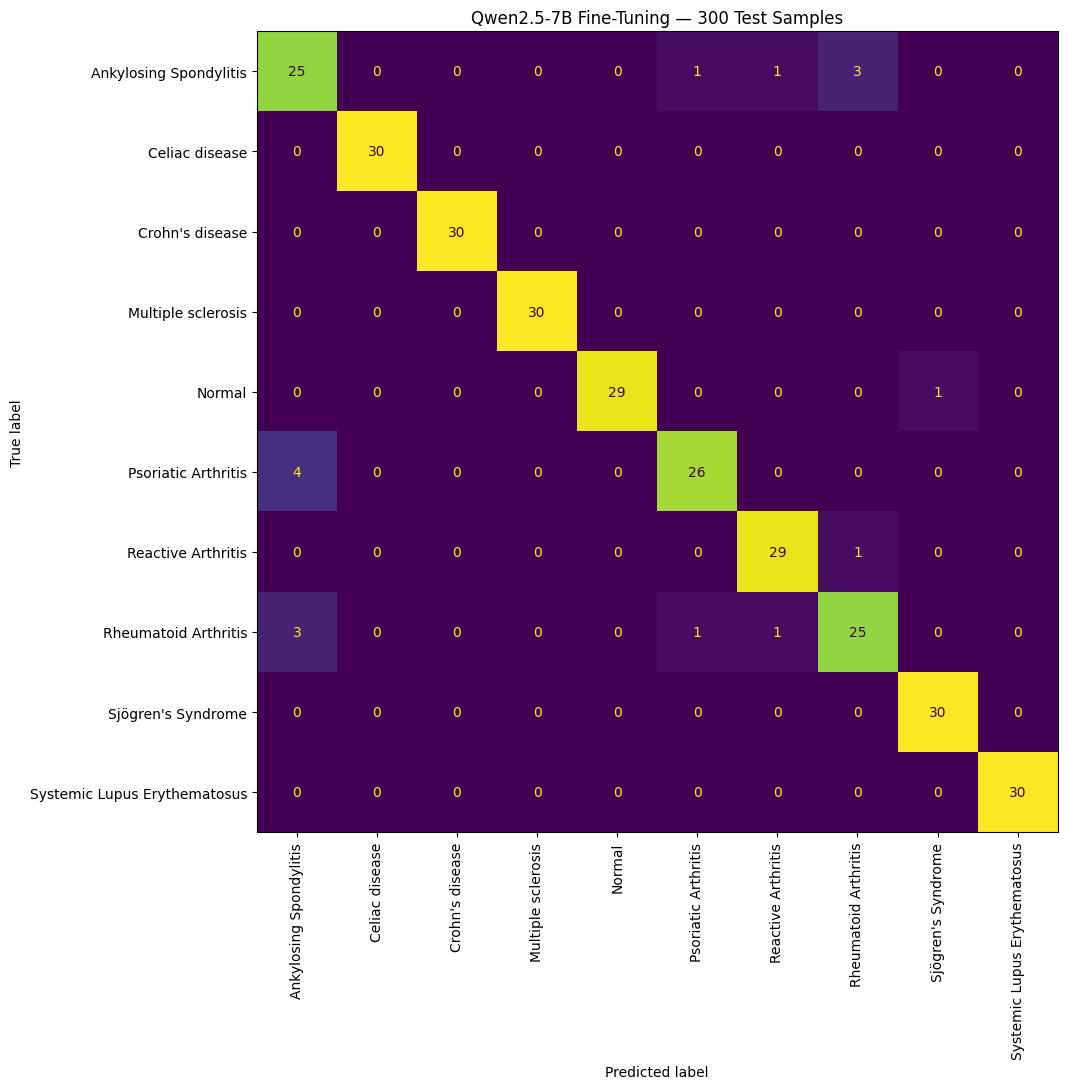

Confusion matrix saved: /content/drive/MyDrive/ImmunoAI_Qwen25_7B_FineTuned/confusion_matrix.png


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

accuracy = accuracy_score(true_labels, predictions)

macro_precision = precision_score(
    true_labels, predictions,
    labels=classes,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    true_labels, predictions,
    labels=classes,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    true_labels, predictions,
    labels=classes,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    true_labels, predictions,
    labels=classes,
    average="weighted",
    zero_division=0
)

print(f"Test accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro precision: {macro_precision:.4f}")
print(f"Macro recall: {macro_recall:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Weighted F1: {weighted_f1:.4f}")

print("\nClassification report:")
print(classification_report(
    true_labels,
    predictions,
    labels=classes,
    zero_division=0,
    digits=4
))

cm = confusion_matrix(
    true_labels,
    predictions,
    labels=classes
)

fig, ax = plt.subplots(figsize=(13, 11))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    values_format="d",
    colorbar=False
)

plt.title("Qwen2.5-7B Fine-Tuning — 300 Test Samples")
plt.tight_layout()

cm_path = os.path.join(
    DRIVE_OUTPUT,
    "confusion_matrix.png"
)

plt.savefig(cm_path, dpi=200, bbox_inches="tight")
plt.show()

print("Confusion matrix saved:", cm_path)

In [14]:
# Save the test predictions with the original clinical features.
results_df = test_300[expected_features + ["Disease"]].copy()

results_df["Predicted_Disease"] = predictions
results_df["Raw_Model_Output"] = raw_outputs
results_df["Correct"] = (
    results_df["Disease"] == results_df["Predicted_Disease"]
)

results_path = os.path.join(
    DRIVE_OUTPUT,
    "test_predictions_300.csv"
)

results_df.to_csv(results_path, index=False)

summary = pd.DataFrame([{
    "Model": "Qwen2.5-7B-Instruct",
    "Fine_tuning_method": "Unsloth QLoRA 4-bit",
    "Training_samples": len(train_1500),
    "Test_samples": len(test_300),
    "Classes": len(classes),
    "Accuracy": accuracy,
    "Macro_Precision": macro_precision,
    "Macro_Recall": macro_recall,
    "Macro_F1": macro_f1,
    "Weighted_F1": weighted_f1,
    "Invalid_predictions": sum(
        p not in classes for p in predictions
    )
}])

summary_path = os.path.join(
    DRIVE_OUTPUT,
    "evaluation_summary.csv"
)

summary.to_csv(summary_path, index=False)

display(summary)

print("\nAll outputs saved to:", DRIVE_OUTPUT)
print("Predictions:", results_path)
print("Summary:", summary_path)
print("Confusion matrix:", cm_path)

,Model,Fine_tuning_method,Training_samples,Test_samples,Classes,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Invalid_predictions
0,Qwen2.5-7B-Instruct,Unsloth QLoRA 4-bit,1500,300,10,0.946667,0.947512,0.946667,0.946794,0.946794,0



All outputs saved to: /content/drive/MyDrive/ImmunoAI_Qwen25_7B_FineTuned
Predictions: /content/drive/MyDrive/ImmunoAI_Qwen25_7B_FineTuned/test_predictions_300.csv
Summary: /content/drive/MyDrive/ImmunoAI_Qwen25_7B_FineTuned/evaluation_summary.csv
Confusion matrix: /content/drive/MyDrive/ImmunoAI_Qwen25_7B_FineTuned/confusion_matrix.png
